# Dead & Alive 5.0 : IIT Roorkee Qiskit Fall Fest — Quantum Hackathon in collaboration with IBM

# **Fresher's Prompt**

---

## Instructions

*   Make a copy of this notebook on your Google Drive.
*   Run the three cells in **Getting Started** without making any changes to them. (The only exception: uncomment the install line in the first cell if the required packages are missing from your environment.)
*   Follow the instructions given near the questions carefully. Do not edit cells which contain essential code. (You can create your own cells to test out snippets.)
*   The final notebook is to be submitted as a downloaded `.ipynb` file. The submission form for the Fresher's Prompt will be shared on the website and the Discord server.

## Grading

1. Part A is compulsory: you must attempt it to be considered for the evaluation of Part B and for the participation certificate.
2. All questions are allotted certain points. The required points are written before each cell/problem.
3. The total score will be used to decide the rank. In the case where people have the same score, we shall look at code quality and approach.
4. Short comments explaining your code are expected.

## Submissions

**Submission Form:** *[google form](https://docs.google.com/forms/d/e/1FAIpQLSeViyXT3dogIu_JScgxS8PHtGax2yk5VNxupaKHcuTxeYA2vA/viewform?usp=sharing&ouid=116330206919175221861)*

**Deadline: 4th October 2026, 9 PM**

---

## Contents

| Part | Challenge | Topic |
|:---:|:---|:---|
| — | **Getting Started** | Environment setup, library imports and grader imports |
| **A** | Challenge 1 | Superposition |
| **A** | Challenge 2 | Grover's Algorithm |
| **A** | Challenge 3 | Variational Quantum Eigensolver (VQE) |
| **B** | Challenge 4 | Fault-Tolerant Quantum Computing: Gate Synthesis & Pareto Architecture Optimization |

## Participant Details

*Fill in before submitting.*

| Field | Details |
|:---|:---|
| **Name** | |
| **Email ID** | |

---

# Getting Started

Run the three cells below, in order, to get the environment set.

1. **Setup:** installs the required packages (only needed if they are missing from your environment).
2. **Libraries:** imports every library used in Part A. *(Part B has its own imports inside its evaluation harness.)*
3. **Grader:** imports the `qc_grader` functions used to check your answers.

In [ ]:
# Setup (run once, only if the packages are missing from your environment).
# Uncomment the line below, run the cell, then restart the kernel/runtime.
%pip install --upgrade qiskit'[visualization]' numpy scipy matplotlib pylatexenc qc-grader

# Alternative (Qiskit only):
# !pip install qiskit

### IBM Quantum Account Setup & Autograder Notice

> **Important Note:**
> * Linking your IBM Quantum account is **only required if you want live feedback from the autograder (`qc_grader`)**.
> * If you prefer not to create an account or provide an API token, you can **safely skip these setup cells**.
> * **If skipped, all `grade_*` and `check_progress` cells will raise authentication or connection errors — you can safely ignore these grader failures.** Your submitted notebook will still be evaluated based on your code and outputs.
>
> To enable the grader:
> 1. Log in or sign up at [quantum.ibm.com](https://quantum.ibm.com/).
> 2. Copy your API token from your account profile.
> 3. Paste it into `IBM_QUANTUM_TOKEN` below and execute the cell.

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

# Paste your API token below to enable the qc_grader (optional).
# If left as-is or skipped, you can safely ignore any subsequent autograder errors.
IBM_QUANTUM_TOKEN = "YOUR_API_KEY_HERE"

if IBM_QUANTUM_TOKEN and IBM_QUANTUM_TOKEN != "YOUR_API_KEY_HERE":
    try:
        QiskitRuntimeService.save_account(
            channel="ibm_quantum_platform",
            token=IBM_QUANTUM_TOKEN,
            overwrite=True,
            set_as_default=True
        )
        print("✅ Account saved. qc_grader checks will run normally.")
    except Exception as err:
        print(f"⚠️ Failed to save account: {err}")
else:
    print(
        "ℹ️ No API token provided.\n"
        "   Local simulations will work fine, but qc_grader cells will fail.\n"
        "   You can safely ignore any autograder errors if you choose not to link an account."
    )

ℹ️ No API token provided.
   Local simulations will work fine, but qc_grader cells will fail.
   You can safely ignore any autograder errors if you choose not to link an account.


In [ ]:
# Verify account status
try:
    service = QiskitRuntimeService()
    account = service.active_account()
    if account:
        print(f"✅ IBM Quantum account active (Channel: {account.get('channel')})")
    else:
        print("ℹ️ No active account detected. You can safely proceed with local simulation and ignore grader errors.")
except Exception:
    print("ℹ️ No active account detected. You can safely proceed with local simulation and ignore grader errors.")

qiskit_runtime_service.__init__:WARNING:2026-10-07 18:27:54,300: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


✅ IBM Quantum account active (Channel: ibm_quantum_platform)


In [ ]:
#@title Libraries used in Part A
import math

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, qpy
from qiskit.circuit import Parameter
from qiskit.circuit.library import grover_operator, MCMTGate, ZGate
from qiskit.primitives import StatevectorSampler, StatevectorEstimator
from qiskit.quantum_info import Statevector, Operator, Pauli, SparsePauliOp
from qiskit.visualization import plot_histogram, plot_distribution, plot_bloch_multivector

In [ ]:
#@title Auto-grader
# Grader: progress checker and graded exercises for every challenge
from qc_grader.challenges.fallfest_2026 import check_progress

from qc_grader.challenges.fallfest_2026.superposition import (
    grade_superposition_ex1, grade_superposition_ex2, grade_superposition_ex3,
    grade_superposition_ex4, grade_superposition_ex5, grade_superposition_ex6,
    grade_superposition_ex7, grade_superposition_ex8,
)

from qc_grader.challenges.fallfest_2026.grovers import (
    grade_grovers_ex1, grade_grovers_ex2, grade_grovers_ex3,
    grade_grovers_ex4, grade_grovers_ex5, grade_grovers_ex6,
    grade_grovers_ex7, grade_grovers_ex8,
)

from qc_grader.challenges.fallfest_2026.vqe import (
    grade_vqe_ex1, grade_vqe_ex2, grade_vqe_ex3, grade_vqe_ex4,
    grade_vqe_ex5, grade_vqe_ex6, grade_vqe_ex7, grade_vqe_ex8,
    grade_vqe_ex9, grade_vqe_ex10, grade_vqe_ex11, grade_vqe_ex12,
)

---

# Part A

Part A consists of three challenges: **Superposition**, **Grover's Algorithm** and the **Variational Quantum Eigensolver (VQE)**. Each challenge combines guided code tasks (10 points each) with graded review questions. Part A is compulsory.

---

## Challenge 1: Superposition

### 1. Classical Coin vs. Quantum Coin

A fair classical coin is a *probabilistic state*: $S(coin) = \frac12|up\rangle + \frac12|down\rangle$, where the coefficients are the probabilities.

A qubit is measured as $|0\rangle$ or $|1\rangle$. Starting in $|0\rangle$, a **Hadamard gate** creates the equal superposition

$$|\psi\rangle = \tfrac{1}{\sqrt2}|0\rangle + \tfrac{1}{\sqrt2}|1\rangle .$$

Now the probabilities are the **squares** of the coefficients, and the coefficients can be **complex**. Measured in the usual ($Z$) basis, this looks exactly like a coin flip, but we will see it is not.

#### Code Task 1: The Quantum Coin [10 Points]
Build the one-qubit "quantum coin", measure it, and sample it 2000 times with `StatevectorSampler`.

P(0) = 0.4935


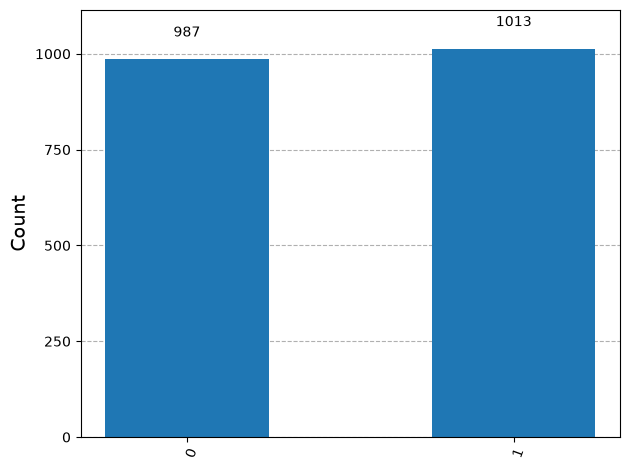

In [ ]:
coin = QuantumCircuit(1)
# TODO 1a: put the qubit in an equal superposition

# Applying Hamdard gate on the qubit indexed 0.
# It changes from its default |0> to (|0> + |1>)/sqrt(2), an equally probable state.
coin.h(0)

# TODO 1b: measure all qubits (classical register is named "meas")

# We add a measurement that records the qubit's result into "meas"
coin.measure_all()

# Number of times the circuit is run
shots = 2000

# TODO 1c: sample the circuit - run takes a list of circuits, then use .result()[0].data.meas.get_counts()

# Sampler is used to simulate the circuit
sampler = StatevectorSampler()

# We run the circuit 2000 times and collect the tally, e.g. {"0": 962, "1": 1038}
counts = sampler.run([coin], shots=shots).result()[0].data.meas.get_counts()

# We estimate P(0) as (number of 0 outcomes) / (total shots).
# It returns 0 if "0" never appeared
print("P(0) =", counts.get("0", 0) / shots)

# TODO 1d: in one sentence, what does this histogram NOT tell us about the qubit?
task1_answer = task1_answer = """The histogram does not show that every shot starts
                                 in the same definite state with a well defined phase,
                                 so the near 50/50 result comes from the act of measuring,
                                 unlike a fair classical coin, which is randomly heads
                                 or tails before we look."""
plot_histogram(counts)

### 2. Expectation Values

`Sampler` only measures in the $Z$ basis. To learn more, `Estimator` returns the **expectation value** $\langle\psi|O|\psi\rangle$ of an observable $O$ (a Pauli matrix $X$, $Y$ or $Z$, with eigenvalues $\pm1$). For a classical coin that pays +\$1 / −\$1, the expectation is 0. For $Z$ on our quantum coin it is also 0:

$$\langle\psi|Z|\psi\rangle = \tfrac12(+1)+\tfrac12(-1)=0 .$$

If the quantum coin behaved like a classical coin, $\langle X\rangle$ would be 0 too, since it would be 50/50 between $|+\rangle$ and $|-\rangle$. It is not: for $H|0\rangle$, $\langle X\rangle = 1$, so the outcome along $X$ is *certain*.

#### Code Task 2: Predict, Then Measure [10 Points]
The circuit applies a Hadamard followed by an `S` gate (a PHASE gate with $\phi=\pi/2$). Predict $\langle X\rangle,\langle Y\rangle,\langle Z\rangle$ **by hand**, then compute them with `StatevectorEstimator`.

In [ ]:
# Build a one-qubit circuit; the qubit starts in |0>
state_circ = QuantumCircuit(1)

# Hadamard: |0> becomes (|0> + |1>)/sqrt(2),the |+> state
state_circ.h(0)

# S gate: It multiplies the |1> amplitude by i, giving (|0> + i|1>)/sqrt(2),the |+i> state
state_circ.s(0)

# TODO 2a: hand-calculated predictions (numbers in [-1, 1])

# Z: P(0) = P(1) = 1/2, so the average is 0
# X: the state is an equal mix of |+> and |->, so +1 and -1 are equally likely: <X> = 0
# Y: the state is exactly |+i>, which always gives the answer +1 for Y: <Y> = 1
predicted = {"X": 0, "Y": 1, "Z": 0}

# TODO 2b: observables

# We reform Pauli operators X, Y, Z as objects the Estimator can use
obs_x, obs_y, obs_z = SparsePauliOp("X"), SparsePauliOp("Y"), SparsePauliOp("Z")

# TODO 2c: one (circuit, observable) pub per observable, then run the estimator

# Each pub pairs the circuit with 1 observable, so we get three different expectation values
pubs = [(state_circ, obs_x), (state_circ, obs_y), (state_circ, obs_z)]

# This is the estimator that computes expectation values exactly using the statevector
estimator = StatevectorEstimator()

# We run all three pubs and wait for the results
result = estimator.run(pubs).result()

# This pulls out the expectation value (evs) of each pub and labels it X, Y or Z by its position
measured = {k: float(result[i].data.evs) for i, k in enumerate("XYZ")}

for k in "XYZ":
    print(f"<{k}> predicted = {predicted[k]}   measured = {measured[k]:.3f}")

<X> predicted = 0   measured = 0.000
<Y> predicted = 1   measured = 1.000
<Z> predicted = 0   measured = 0.000


### 3. Phase and Interference

A quantum state $|\psi\rangle = c_1|0\rangle + c_2|1\rangle$ has complex coefficients $c_i = |c_i|e^{i\phi_i}$. The angle $\phi_i$ is the **phase**; it decides how terms **interfere** (add or cancel like waves). Only the *relative* phase matters.

<p align="center">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/quantum-mechanics/superposition-with-qiskit/complexplane.avif" alt="A circle in a complex plane. The quantum state is represented as an arrow of length 1 that can rotate to any point on the circle." width="450">
</p>

The Hadamard sends $|0\rangle \to \frac{1}{\sqrt2}(|0\rangle+|1\rangle)$ and $|1\rangle \to \frac{1}{\sqrt2}(|0\rangle-|1\rangle)$; the minus sign is a phase of $\pi$. Applying the Hadamard *twice* is not "flipping a coin twice": the $|1\rangle$ terms cancel (destructive interference) and the $|0\rangle$ terms add (constructive interference). A PHASE gate $P(\phi)$ changes the relative phase between the two terms.

#### Code Task 3: Interference [10 Points]
Use `Statevector(qc).probabilities()` (no measurement gates needed) for the three experiments. Circuits are $H$ – (optional $P(\phi)$) – $H$ on $|0\rangle$.

In [ ]:
# 3a: H then H
qc_hh = QuantumCircuit(1)

# The first H puts |0> into (|0> + |1>)/sqrt(2)
qc_hh.h(0)

# The second H undoes the first: the |1> terms cancel (destructive interference)

# and the |0> terms add up (constructive interference), so we return to |0>
qc_hh.h(0)

# 3b: H, then a phase shift of pi, then H
qc_pi = QuantumCircuit(1)

# H creates the equal superposition (|0> + |1>)/sqrt(2)
qc_pi.h(0)

# A phase of pi turns the |1> amplitude from +1/sqrt(2) into -1/sqrt(2), giving (|0> - |1>)/sqrt(2) = |->
qc_pi.p(np.pi, 0)

# The last H maps |-> to |1>, so now the |0> terms cancel and the |1> terms add up
qc_pi.h(0)

# 3c: choose phi in [0, 2*pi] so that P(0) = 25% and P(1) = 75%

# TODO: derive P(0) as a function of phi for H - P(phi) - H, and write your derivation here
task3_derivation = """H|0> = (|0> + |1>)/sqrt(2)
P(phi) multiplies only the |1> amplitude by e^(i*phi): (|0> + e^(i*phi)|1>)/sqrt(2)
The second H gives (1/2)[(1 + e^(i*phi))|0> + (1 - e^(i*phi))|1>]
So P(0) = |1 + e^(i*phi)|^2 / 4 = (2 + 2cos(phi)) / 4 = (1 + cos(phi))/2 = cos^2(phi/2)
and P(1) = sin^2(phi/2).
Setting P(0) = 1/4: cos^2(phi/2) = 1/4 -> cos(phi/2) = 1/2 -> phi/2 = pi/3 -> phi = 2*pi/3
(check: P(0) = (1 + cos(2*pi/3))/2 = (1 - 1/2)/2 = 1/4, P(1) = 3/4).
phi = 2*pi/3 is the solution given by the principal branch; 4*pi/3 also works by symmetry.
Sanity checks: phi = 0 gives P(0) = 1 (task 3a) and phi = pi gives P(0) = 0 (task 3b)."""

phi = 2 * np.pi / 3

qc_phi = QuantumCircuit(1)

# Same H - P(phi) - H structure, now with the phase phi derived above
qc_phi.h(0)
qc_phi.p(phi, 0)
qc_phi.h(0)

for name, qc in [("3a", qc_hh), ("3b", qc_pi), ("3c", qc_phi)]:
    print(name, "P(0), P(1) =", np.round(Statevector(qc).probabilities(), 3))

3a P(0), P(1) = [1. 0.]
3b P(0), P(1) = [0. 1.]
3c P(0), P(1) = [0.25 0.75]


### 4. A Better Analogy: $\sqrt{\text{NOT}}$ and Rotations

Think of the coin sitting on a table. NOT flips it (a $180^\circ$ rotation about $x$). A $\sqrt{\text{NOT}}$ is a $90^\circ$ rotation about $x$: the coin stands on its edge. Measuring along $x$ or $z$ gives 50/50 random results, but along $y$ the result is certain, just like our quantum coin. So a superposition is better pictured as a coin **sitting still at some orientation** than as one spinning in the air.

Every single-qubit gate is a **deterministic, reversible rotation**:
- NOT: $180^\circ$ about $x$ &nbsp;·&nbsp; $\sqrt{\text{NOT}}$: $90^\circ$ about $x$ &nbsp;·&nbsp; PHASE($\phi$): $\phi$ about $z$
- Hadamard: $90^\circ$ about $y$, then $180^\circ$ about $x$

Randomness only appears when we **measure**.

#### Code Task 4: Gates Are Rotations [10 Points]
Two circuits are *equivalent* if they are equal up to a global phase (`Operator(a).equiv(Operator(b))`).

In [ ]:
# 4a: Hadamard as two rotations (gates ry and rx)
h_rot = QuantumCircuit(1)

# Circuits are read left to right, so Ry(pi/2) acts first and Rx(pi) second,
# which is the operator product Rx(pi).Ry(pi/2) (equal to H up to a global phase)
h_rot.ry(np.pi / 2, 0)
h_rot.rx(np.pi, 0)
h_ref = QuantumCircuit(1)
h_ref.h(0)
print("4a: H = Rx(pi).Ry(pi/2) ?", Operator(h_rot).equiv(Operator(h_ref)))

# 4b: sqrt(NOT) applied twice equals NOT (use the gates sx and x)
two_sx = QuantumCircuit(1)

# Two 90-degree rotations about x make one 180-degree rotation about x
two_sx.sx(0)
two_sx.sx(0)
not_ref = QuantumCircuit(1)

# The NOT gate, for comparison
not_ref.x(0)
print("4b: sqrt(NOT)^2 = NOT ?", Operator(two_sx).equiv(Operator(not_ref)))

# 4c: expectation values <X>, <Y>, <Z> of the sqrt(NOT) state (one sx on |0>), computed with Statevector
# A circuit holding the single sx gate that will be applied to the state
sx_circ = QuantumCircuit(1)
sx_circ.sx(0)

# Start from |0> and evolve it by the sx gate
sx_state = Statevector(QuantumCircuit(1)).evolve(sx_circ)

# <X>, <Y>, <Z> of this state. Expected: [0, -1, 0], so Y is certain (the "coin on its edge"),
# while X and Z are 50/50 random. The sign is - because Rx(+90 deg) turns the +z axis towards -y
exp_vals = [sx_state.expectation_value(Pauli(p)) for p in "XYZ"]
print("<X>, <Y>, <Z> =", np.round(np.real(exp_vals), 3))

4a: H = Rx(pi).Ry(pi/2) ? True
4b: sqrt(NOT)^2 = NOT ? True
<X>, <Y>, <Z> = [ 0. -1.  0.]


### 5. The Bloch Sphere

Any isolated qubit state can be written

$$|\psi\rangle = \cos\tfrac{\theta}{2}|0\rangle + e^{i\phi}\sin\tfrac{\theta}{2}|1\rangle ,$$

a point on a sphere of radius 1: the **Bloch vector**. The relative amplitudes set the polar angle $\theta$; the relative phase sets the azimuthal angle $\phi$.

<p align="center">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/quantum-mechanics/superposition-with-qiskit/bloch-sphere.avif" alt="The Bloch sphere: the quantum state is a vector located by polar angles theta and phi." width="350">
</p>

#### Code Task 5: From Amplitudes to a Bloch Vector [10 Points]
Complete the two helper functions, then plot a state on the Bloch sphere.

In [ ]:
def bloch_angles(state):
    """Given amplitudes [c0, c1], return (theta, phi) with phi in [0, 2*pi)."""
    c0, c1 = state

    # TODO 5a: |c0| = cos(theta/2), so theta = 2*arccos(|c0|). The clip protects arccos from rounding errors like 1.0000000002
    theta = 2 * np.arccos(np.clip(np.abs(c0), 0.0, 1.0))

    # TODO 5b: only the relative phase matters, so phi = arg(c1) - arg(c0), wrapped into [0, 2*pi).
    # If either amplitude is 0 the phase is undefined (the vector is on the z axis), so we use 0

    if np.isclose(np.abs(c0), 0) or np.isclose(np.abs(c1), 0):
        phi = 0.0
    else:
        phi = (np.angle(c1) - np.angle(c0)) % (2 * np.pi)
    return theta, phi

def bloch_vector(theta, phi):
    """Return the Bloch vector (x, y, z) as a numpy array."""
    # TODO 5c: spherical coordinates on a sphere of radius 1
    return np.array([np.sin(theta) * np.cos(phi),
                     np.sin(theta) * np.sin(phi),
                     np.cos(theta)])

# self-check
tests = {"|+>": ([1, 1], np.pi/2, 0.0), "|+i>": ([1, 1j], np.pi/2, np.pi/2), "|1>": ([0, 1], np.pi, None),
         "psi": ([0.5, np.sqrt(3)/2*np.exp(1j*np.pi/3)], 2*np.pi/3, np.pi/3)}
for name, (sv, th_e, ph_e) in tests.items():
    sv = np.array(sv, dtype=complex); sv = sv / np.linalg.norm(sv)
    th, ph = bloch_angles(sv)
    print(name, "OK" if np.isclose(th, th_e) and (ph_e is None or np.isclose(ph, ph_e)) else "check again")
print("|bloch_vector| =", np.linalg.norm(bloch_vector(1.0, 2.0)))

# TODO 5d: plot the Bloch vector of the state_circ from Task 2 (H followed by S)
# H then S gives |+i>, so the vector should point along +y, i.e. (0, 1, 0)

plot_bloch_multivector(Statevector(state_circ))
...

|+> OK
|+i> OK
|1> OK
psi OK
|bloch_vector| = 1.0


Ellipsis

### 6. Superposition of *What*?

Whether a state is "in a superposition" depends on the measurement basis: $|+\rangle$ is random in $Z$ but certain in $X$. `Sampler` only measures in $Z$, but we can **rotate first** so that another basis becomes the $Z$ basis.

#### Code Task 6: Measuring in Other Bases [10 Points]
- **6a.** Prepare $|+\rangle$ and measure it in the $X$ basis (add the gate that maps $|+\rangle\to|0\rangle$, $|-\rangle\to|1\rangle$).
- **6b.** Prepare the $\sqrt{\text{NOT}}$ state and measure it in the $Y$ basis (`sdg` followed by one more gate). Which outcome do you expect with certainty?

In [ ]:
sampler = StatevectorSampler()

qc_x = QuantumCircuit(1)

# prepares |+>
qc_x.h(0)

# TODO 6a: basis change
# H maps |+> -> |0> and |-> -> |1>, so a Z measurement after it is an X measurement.
# |+> is an X eigenstate, so we expect "0" every time
qc_x.h(0)
qc_x.measure_all()
print("6a:", sampler.run([qc_x], shots=1000).result()[0].data.meas.get_counts())

qc_y = QuantumCircuit(1)

# prepares the sqrt(NOT) state
qc_y.sx(0)

# TODO 6b: basis change (two gates)
# Sdg then H maps |+i> -> |0> and |-i> -> |1>, which turns a Z measurement into a Y measurement.
# The sqrt(NOT) state is |-i> (<Y> = -1), so we expect "1" every time
qc_y.sdg(0)
qc_y.h(0)
qc_y.measure_all()
print("6b:", sampler.run([qc_y], shots=1000).result()[0].data.meas.get_counts())

# TODO 6c: why must "is this qubit in a superposition?" always be answered with "a superposition of what?"
task6_answer = """Being in a superposition is not a property of the qubit alone,
it depends on the measurement basis.A state that is a superposition of |0> and |1>
(random in the Z basis) can be a single definite eigenstate of another basis. For
example |+> is random in Z but gives a certain result in X, and the sqrt(NOT) state
is random in X and Z but certain in Y. So the question only makes sense once we
name the basis: the same qubit is "in a superposition" of the Z basis states and not
in a superposition of the X basis states."""

6a: {'0': 1000}
6b: {'1': 1000}


### Review Questions

Questions are numbered to match the grader: Question *N* is graded by `grade_superposition_exN`. Replace the placeholder `answer` in each cell with your own answer and run the cell.

#### Critical Concepts

- While the measurement of a qubit in a superposition is probabilistic, like flipping a coin, the superposition state itself behaves differently than a flipping coin.
- A main difference between a classical probability distribution and a superposition is that the superposition has *phase* coherence, which allows it to interfere constructively or destructively.
- The state of a single, isolated qubit can be visualized as a point on the "Bloch sphere," where the relative amplitudes determine the polar angle $\theta$ and the relative phases determine the azimuthal angle $\phi$.
- All single-qubit quantum gates can be viewed as rotations of the vector on this sphere.

#### True / False

**Question 1.**
 A quantum superposition is basically the same as a probabilistic event in classical physics, like flipping a coin.

In [ ]:
answer = False # Replace with True or False
grade_superposition_ex1(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:27:57,049: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct, False: unlike a coin flip, a superposition has phase coherence and can interfere.
You scored 1 on this exercise.


**Question 2.** The length of the Bloch vector describing the state of a single isolated qubit is always 1.

In [ ]:
answer = True  # Replace with True or False
grade_superposition_ex2(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:27:59,948: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct, True: an isolated qubit lies on the radius-1 Bloch sphere, so its vector has length 1.
You scored 1 on this exercise.


**Question 3.** Single-qubit quantum gates do not change the length of the Bloch vector.

In [ ]:
answer = True  # Replace with True or False
grade_superposition_ex3(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:03,180: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct, True: single-qubit gates rotate the Bloch vector, changing direction but not length.
You scored 1 on this exercise.


#### Multiple Choice

**Question 4.** Select the correct Bloch vector that represents the state $|\Psi\rangle = \sqrt{\frac{1}{3}}|0\rangle + e^{i \pi / 4} \sqrt{\frac{2}{3}}|1\rangle$:

<p align="center">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/quantum-mechanics/superposition-with-qiskit/mc-question.avif" alt="mc-question" width="600">
</p>

- **a.** Vector nearly along $+x$
- **b.** Halfway between $+x$ and $+y$, slightly below the $xy$ plane
- **c.** Between $+x$ and $-y$, slightly above the $xy$ plane
- **d.** Along $-x$

In [ ]:
answer = "b"  # Replace with your answer: "a", "b", "c", or "d"
grade_superposition_ex4(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:06,682: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct, (b): theta = 2*arccos(sqrt(1/3)) is about 109.5 degrees (below the xy plane) and phi = pi/4 (between +x and +y).
You scored 1 on this exercise.


**Question 5.** The Bloch sphere describes a qubit's (select all that apply):

- **a.** amplitude
- **b.** entanglement with other qubits
- **c.** phase
- **d.** color
- **e.** probability of measurement outcomes

In [ ]:
answer = ["a", "c", "e"]  # Replace with a list of your answers, e.g. ["a", "c", "e"]
grade_superposition_ex5(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:10,048: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct: the Bloch sphere encodes a qubit amplitude (a), phase (c), and measurement probabilities (e).
You scored 1 on this exercise.


#### Discussion

**Question 6.** Why can the state of a qubit be visualized on the Bloch sphere, but the probability distribution of a coin flip cannot?

In [ ]:
answer = """A single isolated qubit state is completely described by two real numbers,
a polar angle theta (from the relative amplitudes) and an azimuthal angle phi (from
the relative phase), so it maps to a point on a sphere of radius 1. A classical coin
flip is just a probability distribution (p, 1-p) with p and 1-p non-negative and adding
up to 1. It has only one free number and no phase, so it lives on a line segment and has
no angles to show. The sphere is needed because the qubit's complex amplitudes carry phase,
which controls interference."""
grade_superposition_ex6(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:12,965: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


A qubit state has both an amplitude (polar angle theta) and a phase (azimuthal angle phi), fixing one point on the Bloch sphere. A coin flip is only a probability distribution with no phase, so nothing fixes its position around the equator.
You scored 1 on this exercise.


**Question 7.** Why is a coin flipping in the air not the best analogy to a quantum superposition state? What aspect of superpositions are not captured in this analogy?

In [ ]:
answer = """A coin spinning in the air is a classical object that is really heads
or tails at every instant and we are only ignorant of which. This is just a
probabilistic mixture. A qubit in a superposition is not secretly 0 or 1 before
measurement: it is in a definite pure state, like a coin lying still at some orientation,
and it can give a certain result when measured in another basis (e.g. |+> always gives
+ in the X basis). The analogy misses the phase: the complex amplitudes have relative
phases, so superposition terms can interfere constructively or destructively (H applied
twice returns |0>, whereas flipping a coin twice stays random). It also hides that gates
are reversible rotations and that randomness only appears on measurement."""
grade_superposition_ex7(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:15,840: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


A flipping coin captures the random 50/50 outcome but not the phase. A superposition carries phase, so its terms interfere (two Hadamards return the qubit to |0>) and outcomes are predictable along the right axis. A coin sitting still on its edge is a closer analogy.
You scored 1 on this exercise.


#### Challenge Problem

**Question 8.** Use Qiskit to create a circuit that transforms the state $|0\rangle$ to the state $\frac{\sqrt{3}}{2}|0\rangle + \frac{1}{2}e^{i \frac{5\pi}{6}}|1\rangle$.

In [ ]:
# Target: sqrt(3)/2 |0> + (1/2) e^(i*5*pi/6) |1>
# cos(theta/2) = sqrt(3)/2 -> theta = pi/3 ; relative phase phi = 5*pi/6
qc_ex8 = QuantumCircuit(1)

# sets the amplitudes: cos(pi/6)|0> + sin(pi/6)|1> = sqrt(3)/2|0> + 1/2|1>
qc_ex8.ry(np.pi / 3, 0)

      # adds the relative phase e^(i*5*pi/6) to the |1> amplitude
qc_ex8.p(5 * np.pi / 6, 0)

# Verify against the target state (should print True)
target_ex8 = Statevector([np.sqrt(3) / 2, 0.5 * np.exp(1j * 5 * np.pi / 6)])

print("Matches target:", Statevector(qc_ex8).equiv(target_ex8))

answer = """qc = QuantumCircuit(1)
qc.ry(pi/3, 0)       # theta = pi/3: cos(theta/2) = sqrt(3)/2, sin(theta/2) = 1/2
qc.p(5*pi/6, 0)      # phi = 5*pi/6: relative phase of the |1> amplitude
Resulting state: sqrt(3)/2 |0> + (1/2) e^(i 5pi/6) |1>"""
grade_superposition_ex8(answer)

Matches target: True
Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:21:17,928: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Matching cos(theta/2)=sqrt(3)/2 and sin(theta/2)=1/2 gives theta=pi/3, phi=5*pi/6. One valid circuit:

    from qiskit import QuantumCircuit
    import numpy as np
    qc = QuantumCircuit(1)
    qc.ry(np.pi/3, 0)
    qc.rz(5*np.pi/6, 0)

R_y(pi/3) sets the amplitudes and R_z(5*pi/6) the relative phase; qc.u(np.pi/3, 5*np.pi/6, 0, 0) is equivalent up to global phase.
You scored 1 on this exercise.


#### Check Your Progress

Run the cell below to review your progress in this challenge. Its output must be visible in the submitted notebook.

In [ ]:
check_progress("superposition")

Fetching your progress. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:18,254: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


📊 Your progress

Lab "superposition" — 8/8 passed, score 8.0
  ✅ ex1 — score 1.0
  ✅ ex2 — score 1.0
  ✅ ex3 — score 1.0
  ✅ ex4 — score 1.0
  ✅ ex5 — score 1.0
  ✅ ex6 — score 1.0
  ✅ ex7 — score 1.0
  ✅ ex8 — score 1.0


---

## Challenge 2: Grover's Algorithm

### 1. Unstructured Search and the Grover Operator

Given $N=2^n$ items and an oracle $f(x)$ that returns 1 only for the marked item(s), a classical search needs about $N/2$ queries. **Grover's algorithm** needs only $O(\sqrt N)$, a *quadratic* speedup, and no quantum algorithm can do better for unstructured search. The oracle is a black box: we may *query* it, not look inside.

The circuit has these stages:
1. **Superposition:** Hadamard gates on all qubits.
2. **Marking:** the phase oracle $Z_f:|x\rangle\to(-1)^{f(x)}|x\rangle$ puts a "−" on the target state(s).
3. **Diffusion:** $H^{\otimes n}\,Z_\text{OR}\,H^{\otimes n}$, where $Z_\text{OR}$ flips the sign of every state except $|0\rangle^{\otimes n}$.
4. **Repeat** the marking + diffusion pair (together the *Grover operator*), then **measure**.

<p align="center">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/computer-science/grovers/grover-circuit-diagram-2.avif" alt="Basic Grover circuit diagram for four qubits." width="600">
</p>

Marking alone does not change measurement probabilities, but the Hadamard layers turn the relative sign into a change in probability.

#### Worked Example: Two Qubits
With the oracle marking $|01\rangle$: $|\psi_1\rangle=\frac12(|00\rangle+|01\rangle+|10\rangle+|11\rangle)$, after the oracle $|\psi_2\rangle=\frac12(|00\rangle-|01\rangle+|10\rangle+|11\rangle)$, and after the whole circuit $|\psi_5\rangle=|01\rangle$ with 100% probability.

<p align="center">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/computer-science/grovers/grover-circuit-diagram-2-q-ex.avif" alt="Two-qubit Grover circuit with labeled states." width="600">
</p>

#### Code Task 1: The Two-Qubit Example in Qiskit [10 Points]
Build the circuit above with $|01\rangle$ marked. Qiskit writes bitstrings as $|q_1q_0\rangle$, so qubit 1 must be $0$ and qubit 0 must be $1$. A phase flip on one basis state can be made from a `cz` (phase on $|11\rangle$) surrounded by `x` gates on the qubits that must be $0$. $Z_\text{OR}$ is, up to a global phase, the same trick applied to $|00\rangle$ instead.

In [ ]:
qc = QuantumCircuit(2)

# |psi_1>
qc.h([0, 1])

# TODO 1a: oracle Z_f marking |01>
# In Qiskit |01> means q1 = 0 and q0 = 1. CZ gives a "-" only to |11>,
# so we first flip q1 with X to turn |01> into |11>, apply CZ, then undo the X
qc.x(1)
qc.cz(0, 1)
qc.x(1)

# |psi_3>
qc.h([0, 1])

# TODO 1b: Z_OR (flip the sign of every state except |00>, up to a global phase)
# Same trick on |00>: X on both qubits turns |00> into |11>, CZ flips its sign, X undoes it.
# This flips only |00>, which equals Z_OR up to a global phase of -1
qc.x([0, 1])
qc.cz(0, 1)
qc.x([0, 1])

# |psi_5>
qc.h([0, 1])

print(qc.draw())

# expect {'01': 1.0}
print("Probabilities:", Statevector(qc).probabilities_dict())

     ┌───┐        ┌───┐┌───┐        ┌───┐┌───┐
q_0: ┤ H ├──────■─┤ H ├┤ X ├──────■─┤ X ├┤ H ├
     ├───┤┌───┐ │ ├───┤├───┤┌───┐ │ ├───┤├───┤
q_1: ┤ H ├┤ X ├─■─┤ X ├┤ H ├┤ X ├─■─┤ X ├┤ H ├
     └───┘└───┘   └───┘└───┘└───┘   └───┘└───┘
Probabilities: {np.str_('00'): np.float64(9.071053470133364e-35), np.str_('01'): np.float64(0.9999999999999991), np.str_('10'): np.float64(1.5955770627550177e-68), np.str_('11'): np.float64(5.577060207443597e-34)}


### 2. The Geometric Picture and the Number of Iterations

Split the state into the target component $|A_1\rangle$ and everything else $|A_0\rangle$ (orthogonal). The initial superposition sits at a small angle $\theta$ from $|A_0\rangle$. An operator $2|v\rangle\langle v|-I$ is a reflection about $|v\rangle$. The oracle reflects about $|A_0\rangle$, and the diffusion $H^{\otimes n}(2|0\rangle\langle0|-I)H^{\otimes n}=2|u\rangle\langle u|-I$ reflects about the uniform state $|u\rangle$. Two reflections make a **rotation by $2\theta$** toward $|A_1\rangle$.

<p align="center">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/computer-science/grovers/grover-geometric-setup.avif" alt="Geometric picture of the quantum state." width="350">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/computer-science/grovers/grover-geometric-reflections.avif" alt="The Grover operator as a rotation." width="350">
</p>

We want a total rotation of about $\pi/2$. With $|A_1|$ solutions among $N$ states, $\theta=\sin^{-1}\sqrt{|A_1|/N}$ and the optimal number of iterations is

$$t \approx \frac{\pi}{4}\sqrt{\frac{N}{|A_1|}}-\frac12 \qquad\text{(in the code we use }t=\left\lfloor \frac{\pi}{4\,\sin^{-1}\!\sqrt{|A_1|/N}}\right\rfloor\text{)}.$$

Too many iterations rotate **past** the target and the success probability drops again. On noisy hardware, fewer iterations than the optimum can be preferable because the circuit is shallower.

#### Code Task 2: Oracle, Grover Operator, and Search [10 Points]
1. Complete `grover_oracle`, which marks one or more bitstrings with a multi-controlled Z. `MCMTGate(ZGate(), n - 1, 1)` is a Z controlled on all $n$ qubits. Qubits that must be $|0\rangle$ in the target need an `x` gate before and after it. Remember Qiskit's bit ordering (qubit 0 is the rightmost bit).
2. Complete `optimal_iterations` with the formula above.
3. Complete `run_grover`, which builds *superposition → Grover operator $t$ times → measurement* and samples it with `StatevectorSampler`.
4. Search for the state `"1110"` among 16 states.

marked index: [14] (expected [14])
optimal number of iterations: 3


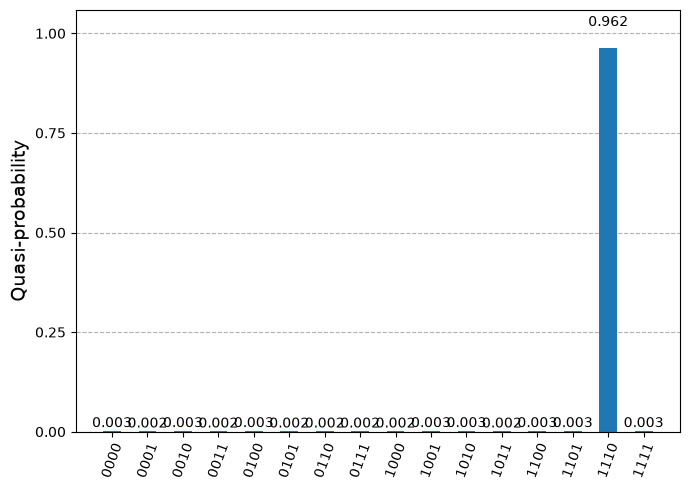

In [ ]:
def grover_oracle(marked_states):
    """Phase oracle that flips the sign of every bitstring in marked_states."""
    if not isinstance(marked_states, list):
        marked_states = [marked_states]
    num_qubits = len(marked_states[0])
    qc = QuantumCircuit(num_qubits)
    for target in marked_states:
        # TODO 2a: Qiskit puts qubit 0 on the right of a bitstring, so we reverse the string
        # to make position i of rev_target correspond to qubit i
        rev_target = target[::-1]
        # TODO 2b: qubits that must be 0 in the target (they need an X to act as an "open control")
        zero_inds = [i for i, bit in enumerate(rev_target) if bit == "0"]
        # TODO 2c: X on zero_inds, multi-controlled Z on all qubits, X on zero_inds again.
        # The Z is applied only if all qubits are |1> after the X gates, i.e. only for the target
        qc.x(zero_inds)
        qc.compose(MCMTGate(ZGate(), num_qubits - 1, 1), inplace=True)
        qc.x(zero_inds)
    return qc


def optimal_iterations(num_qubits, num_marked):
    # TODO 2d: floor( pi / (4 * asin(sqrt(num_marked / N))) ) with N = 2**num_qubits
    N = 2 ** num_qubits
    return math.floor(math.pi / (4 * math.asin(math.sqrt(num_marked / N))))


def run_grover(oracle, num_marked, shots=10_000, iterations=None):
    """Run Grover's search with the given oracle and return the measurement counts."""
    grover_op = grover_operator(oracle)
    n = grover_op.num_qubits
    if iterations is None:
        iterations = optimal_iterations(n, num_marked)

    qc = QuantumCircuit(n)
    # TODO 2e: even superposition, `iterations` applications of the Grover operator, then measure all qubits
    # Hadamard on every qubit gives the uniform superposition over all 2^n states
    qc.h(range(n))
    # Each application of the Grover operator rotates the state a bit closer to the marked state(s)
    for _ in range(iterations):
        qc.compose(grover_op, inplace=True)
    # measure_all creates the classical register named "meas" used below
    qc.measure_all()

    result = StatevectorSampler().run([qc], shots=shots).result()
    return result[0].data.meas.get_counts()


# Search for "1110"
marked_states = ["1110"]
oracle = grover_oracle(marked_states)

# self-check: only the entry of the marked state should be -1
signs = np.round(np.diag(Operator(oracle).data).real).astype(int)
print("marked index:", [i for i, s in enumerate(signs) if s == -1], "(expected [14])")

print("optimal number of iterations:", optimal_iterations(4, 1))
dist = run_grover(oracle, num_marked=1)
plot_distribution(dist)

#### Code Task 3: More Iterations Is Not Always Better [10 Points]
Study how the success probability depends on the number of Grover iterations, for one marked state and for two marked states among 16 (`"1110"` and `"0001"`). Compute exact probabilities with `Statevector` (no sampling), plot them, and compare the peaks with `optimal_iterations`.

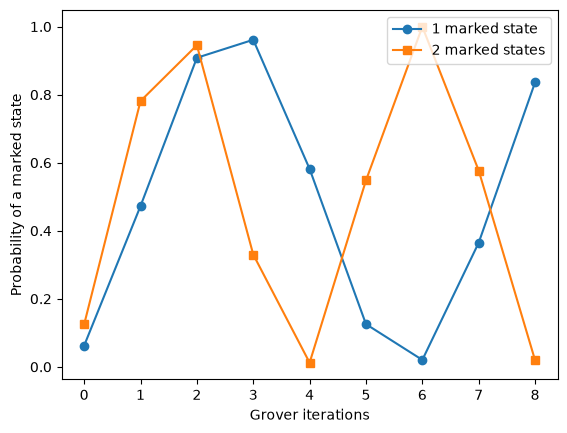

best t, one marked state : 3   formula: 3
best t, two marked states: 6   formula: 2


In [ ]:
def success_probability(marked_states, t):
    """Probability of measuring a marked state after t Grover iterations."""
    oracle = grover_oracle(marked_states)
    grover_op = grover_operator(oracle)
    qc = QuantumCircuit(oracle.num_qubits)

    # TODO 3a: superposition, then t applications of the Grover operator (no measurement)

    qc.h(range(oracle.num_qubits))
    for _ in range(t):
        qc.compose(grover_op, inplace=True)
    probs = Statevector(qc).probabilities_dict()

    # TODO 3b: total probability of all marked states (add up their entries; missing keys mean probability 0)

    return sum(probs.get(s, 0.0) for s in marked_states)


ts = range(0, 9)
one = [success_probability(["1110"], t) for t in ts]
two = [success_probability(["1110", "0001"], t) for t in ts]

# TODO 3c: plot both curves against t (with labels and a legend)

fig, ax = plt.subplots()
ax.plot(list(ts), one, marker="o", label="1 marked state")
ax.plot(list(ts), two, marker="s", label="2 marked states")
ax.legend()
ax.set_xlabel("Grover iterations")
ax.set_ylabel("Probability of a marked state")
plt.show()

print("best t, one marked state :", int(np.argmax(one)), "  formula:", optimal_iterations(4, 1))
print("best t, two marked states:", int(np.argmax(two)), "  formula:", optimal_iterations(4, 2))

# TODO 3d: why does the probability fall after the peak, and why does a second marked state change the best t?

task3_answer = """Each Grover iteration rotates the state by 2*theta in the plane spanned by the marked and unmarked
states, so the success probability is sin^2((2t+1)*theta). It peaks when the total rotation is about pi/2.
If we keep iterating, the state is rotated past the marked state and the probability falls again
(the curve is periodic, like a sine wave). With a second marked state the fraction of solutions
is larger, so the starting angle theta = asin(sqrt(M/N)) is bigger (about sqrt(2) times). Each iteration therefore
rotates further and we reach pi/2 sooner, which gives a smaller best t (2 instead of 3), and
overshooting also happens sooner. This matches the formula t ~ (pi/4)*sqrt(N/M).
Note: the success probability is periodic in t, so the printed argmax for two marked states over t = 0..8 is the
later, higher peak at t = 6 (probability 1.0). The first peak is at t = 2 (probability about 0.94), which
is the optimal_iterations value and the cheapest choice, since extra iterations only add circuit depth."""

### 3. A Two-Party Query Game

Grover's algorithm fits the **query model**: one party controls the oracle, the other finds the answer using only queries, never looking inside. You will pair up with another team. Each team chooses a secret bitstring (3 to 5 bits), builds its oracle, and saves it to a file with `qpy`. You exchange files and use Grover's algorithm to find each other's secret.

#### Code Task 4: Find Your Partner's Secret State [10 Points]
Use the functions from Task 2. **Do not draw or print the partner's oracle**: that would break the query model. Tell your partner how many states you marked. *(load your own file.)*

In [ ]:
# Your oracle
secret = ["101"]                      # TODO 4a: your secret bitstring(s), 3-5 bits each
my_oracle = grover_oracle(secret)

# TODO 4b: save my_oracle to "my_oracle.qpy" with qpy.dump, then send the file to your partner
# qpy.dump writes the circuit to a binary file that the partner can load with qpy.load
with open("my_oracle.qpy", "wb") as f:
    qpy.dump(my_oracle, f)

# NOTE: no real partner file was available while this notebook was prepared, so we create a
# stand-in "partner_oracle.qpy" (only if it does not exist yet) to demonstrate the workflow.
# It uses a different secret that is deliberately NOT printed, to keep the query model.
# If you have a real partner file, put it next to the notebook as "partner_oracle.qpy" and it will be used instead.
import os
if not os.path.exists("partner_oracle.qpy"):
    with open("partner_oracle.qpy", "wb") as f:
        qpy.dump(grover_oracle(["0110"]), f)

In [ ]:
# Your partner's oracle
# TODO 4c: load it with qpy.load (it returns a list of circuits) and take the first circuit
with open("partner_oracle.qpy", "rb") as f:
    circuits = qpy.load(f)          # qpy.load always returns a list of circuits

# the oracle is the first (and only) circuit in the file
oracle_partner = circuits[0]
# (we do not draw or print it, which would break the query model)

# ask your partner how many states they marked
num_marked_states = 1

# TODO 4d: run Grover's search with the optimal number of iterations and plot the distribution

# run_grover uses optimal_iterations automatically when iterations=None
dist = run_grover(oracle_partner, num_marked_states)
plot_distribution(dist)

# The most frequent bitstring is our guess for the secret state
print("My guess for the secret state:", max(dist, key=dist.get))

My guess for the secret state: 0110


In [ ]:
# TODO 4e: repeat with ONE FEWER iteration than the optimum. Do you still find the secret state?
# Then explain why someone might choose fewer iterations than the optimum on real (noisy) hardware.
# Optimal number of iterations for the partner's oracle, minus one
n_partner = oracle_partner.num_qubits
fewer = optimal_iterations(n_partner, num_marked_states) - 1
dist_fewer = run_grover(oracle_partner, num_marked_states, iterations=fewer)
plot_distribution(dist_fewer)
print("Guess with one fewer iteration:", max(dist_fewer, key=dist_fewer.get))

task4_answer = """Yes, we still find the secret state. With one iteration fewer the marked state is not at its maximum
probability but it is still clearly the most likely outcome (the state has only been rotated a little short of
the target). On real hardware every Grover iteration adds many gates (especially the multi-controlled Z, which
becomes many two-qubit gates after transpiling), and each gate adds noise. Fewer iterations means a shallower
circuit and less accumulated error. So the noise-free optimum is not always the best choice: a slightly lower ideal
probability of the marked state can still stand out well above the noise, while the full-depth circuit
may turn into almost random output."""

Guess with one fewer iteration: 0110


### 4. Minesweeper: An Oracle Built from Constraints

Grover's algorithm is most interesting when we can build the oracle from the **constraints** of a problem without knowing the answer: finding a solution is hard, but checking one is easy. Minesweeper is such a problem (it is NP-complete). We use a tiny toy grid.

<p align="center">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/computer-science/grovers/minesweeper-grid.avif" alt="A Minesweeper grid with three blank cells and three numbered cells." width="260">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/computer-science/grovers/minesweeper-grid-labeled.avif" alt="The same grid with the blank cells labeled x0, x1, x2." width="260">
</p>

Let $x_i=1$ mean that blank cell $i$ holds a mine. The numbers give the constraints

$$(x_0 \oplus x_1)\;\land\;(x_1 \oplus x_2)\;\land\;\lnot(x_0 \oplus x_1 \oplus x_2),$$

where $\oplus$ is XOR (exactly one is true; for three variables it is true for an odd number of mines).

**Quantum oracle.** Use three workspace (ancilla) qubits $a_0,a_1,a_2$, one per clause. XOR is computed by CX gates onto the ancilla: applying a `cx` from each input qubit onto the ancilla stores the XOR of those inputs there (an `x` gate on the ancilla stores the NOT). A multi-controlled Z on the three ancillas then flips the phase of the data state that satisfies *all* clauses. Finally we **uncompute** (run the clause circuit backwards) so the ancillas return to $|0\rangle$ and are clean for the next Grover iteration.

#### Code Task 5: Solve the Minesweeper Grid [10 Points]
Build the oracle, turn it into a Grover operator that reflects only over the data qubits (`reflection_qubits=x`), and search with `StatevectorSampler`, measuring only the data qubits.

In [ ]:
# data qubits: mine or no mine
x = QuantumRegister(3, "x")

# workspace qubits, one per clause
a = QuantumRegister(3, "a")

# TODO 5a: the "compute" circuit: write the three clauses into a[0], a[1], a[2]
compute = QuantumCircuit(x, a)
# Clause 1: x0 XOR x1 -> two CX gates onto a[0] store the XOR of the two inputs
compute.cx(x[0], a[0])
compute.cx(x[1], a[0])
# Clause 2: x1 XOR x2 -> stored in a[1]
compute.cx(x[1], a[1])
compute.cx(x[2], a[1])
# Clause 3: NOT(x0 XOR x1 XOR x2) -> three CX gates compute the parity in a[2], then X negates it
compute.cx(x[0], a[2])
compute.cx(x[1], a[2])
compute.cx(x[2], a[2])
compute.x(a[2])

oracle_ms = QuantumCircuit(x, a)
oracle_ms.compose(compute, inplace=True)

# TODO 5b: phase flip when a[0], a[1], a[2] are all |1> (a CCZ: H on a[2], mcx from a[0], a[1], H on a[2])

# A CCZ is a Toffoli sandwiched between Hadamards on the target. It gives "-" only when all clauses are satisfied
oracle_ms.h(a[2])
oracle_ms.mcx([a[0], a[1]], a[2])
oracle_ms.h(a[2])

# TODO 5c: uncompute (undo the clause circuit)

# The inverse of the compute circuit returns the workspace qubits to |0>, leaving only the phase on the solution
oracle_ms.compose(compute.inverse(), inplace=True)

# The reflection (diffusion) acts only on the data qubits x, not on the workspace
grover_op = grover_operator(oracle_ms, reflection_qubits=x)

meas = ClassicalRegister(3, "meas")
qc = QuantumCircuit(x, a, meas)

# TODO 5d: superposition on the data qubits only, optimal_iterations(3, 1) Grover iterations, measure only x into meas

# superposition over all 8 mine layouts (workspace stays |0>)
qc.h(x)

# 2 iterations for 1 solution among 8 states
for _ in range(optimal_iterations(3, 1)):
    qc.compose(grover_op, inplace=True)

# only the data qubits are measured
qc.measure(x, meas)

dist = StatevectorSampler().run([qc], shots=10_000).result()[0].data.meas.get_counts()
plot_distribution(dist)
print("Most likely state:", max(dist, key=dist.get))

# TODO 5e: where are the mines? Why must the workspace qubits be uncomputed?
task5_answer = """The most likely state is 101 (x2 x1 x0), so there are mines in cells x0 and x2 and no mine in x1.
Check: x0 XOR x1 = 1, x1 XOR x2 = 1 and x0 XOR x1 XOR x2 = 0, so NOT of it is 1, all three clauses hold.
The workspace qubits must be uncomputed because after the compute step they hold clause results that depend on x,
so they are entangled with the data qubits. If they were left like that, the Grover diffusion could not interfere
the amplitudes of different data states correctly (the workspace would act like a measurement and destroy the
interference), and the next iteration would also start with a dirty workspace. Uncomputing returns the workspace
to |0>, disentangled, so only the phase flip on the solution remains and the Grover iteration can be repeated."""

Most likely state: 101


### Review Questions

Questions are numbered to match the grader: Question *N* is graded by `grade_grovers_exN`. Replace the placeholder `answer` in each cell with your own answer and run the cell.

#### Critical Concepts

- Whereas classical unstructured search requires O(N) queries, Grover's algorithm requires O(√N) — a quadratic speedup.
- Grover's algorithm involves repeating the Grover operator t times, chosen to maximally amplify the target states.
- Applying fewer than t iterations can still amplify target states and may be preferable on noisy hardware.
- Grover's algorithm fits the query model: one party controls the oracle, another runs the search.
- An oracle can be built from problem constraints (e.g. Minesweeper) rather than from direct knowledge of the answer.

#### True / False

**Question 1.** Grover's algorithm provides an exponential improvement over classical algorithms in the number of queries needed to find a single marked state in unstructured search.

In [ ]:
answer = False  # Replace with True or False
grade_grovers_ex1(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:21,373: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct! Grover's gives a quadratic speedup, O(sqrt(N)) queries, not an exponential one.
You scored 1 on this exercise.


**Question 2.** Grover's algorithm works by iteratively increasing the probability that a solution state will be measured.

In [ ]:
answer = True  # Replace with True or False
grade_grovers_ex2(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:21:28,367: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct! Each Grover iteration rotates the state toward the solution, raising its measurement probability.
You scored 1 on this exercise.


**Question 3.** The more times you iterate the Grover operator, the higher the probability of measuring a solution state.

In [ ]:
answer = False  # Replace with True or False
grade_grovers_ex3(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:24,024: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct! Iterating past the optimal t rotates past |A_1>, so the success probability drops again.
You scored 1 on this exercise.


#### Multiple Choice

**Question 4.** Select the best option to complete the sentence. The best strategy to successfully use Grover's algorithm on modern quantum computers is to iterate the Grover operator...

- **a.** Only once.
- **b.** Always t times, to maximize the solution state(s)' probability amplitude.
- **c.** Up to t times, though fewer may be enough to make solution states stand out.
- **d.** No fewer than 10 times.

In [ ]:
answer = "c"  # Replace with "a", "b", "c", or "d"
grade_grovers_ex4(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:21:34,191: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct! Fewer than t iterations give shallower circuits and lower error rates, and can still make the solution stand out.
You scored 1 on this exercise.


**Question 5.** A phase query circuit is shown below that functions as an oracle to mark a certain state with a phase flip. Which of the following states get marked by this circuit?

<p align="center">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/computer-science/grovers/grover-oracle-question.avif" alt="A simple Grover oracle circuit." width="300">
</p>

<p align="center"><em>A simple Grover oracle circuit.</em></p>

- **a.** |0000⟩
- **b.** |0101⟩
- **c.** |0110⟩
- **d.** |1001⟩
- **e.** |1010⟩
- **f.** |1111⟩

In [ ]:
answer = "b"  # Replace with "a", "b", "c", "d", "e", or "f"
grade_grovers_ex5(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:26,728: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct! X gates wrap the multi-controlled Z on the qubits that are 0 in the target, marking |0101>.
You scored 1 on this exercise.


**Question 6.** Suppose you want to search for three marked states from a set of 128. What is the optimal number of iterations of the Grover operator to maximize the amplitudes of the marked states?

- **a.** 1
- **b.** 3
- **c.** 5
- **d.** 6
- **e.** 20
- **f.** 33

In [ ]:
answer = "c"  # Replace with "a", "b", "c", "d", "e", or "f"
grade_grovers_ex6(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:21:40,221: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Correct! With N=128 and |A_1|=3, t = floor(pi/(4*arcsin(sqrt(3/128)))) = floor(5.11) = 5.
You scored 1 on this exercise.


#### Discussion

**Question 7.** What other problems could you formulate as a Grover search? Think of problems where it is difficult to find a solution but easy to verify one.

In [ ]:
answer = """Any problem where finding a solution is hard but checking one is easy (NP-type problems) can be set up
as a Grover search, because the checking procedure can be turned into an oracle. Examples: Sudoku and other
constraint satisfaction problems, Boolean satisfiability (SAT), graph colouring, the travelling salesperson
problem (is there a tour shorter than L?), finding a password or cryptographic key that matches a given hash,
and factoring (check by multiplying). Grover gives a quadratic speedup for brute-force search in all of these."""
grade_grovers_ex7(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:29,226: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Any problem where a solution is hard to find but easy to verify fits: constraint satisfaction (Sudoku, graph coloring), combinatorial optimization, database and cryptographic key search. The requirement is a quantum oracle that checks the constraints without knowing the solution in advance.
You scored 1 on this exercise.


**Question 8.** Can you see any problems with scaling Grover's algorithm on modern quantum computers?

In [ ]:
answer = """Yes.
(1) The quadratic speedup is small compared with exponential speedups, and good classical
algorithms often exploit structure, so a speedup over them is not guaranteed.
(2) The oracle must be built as a circuit; for real problems it can be deep and costs many gates and ancilla qubits, and
the oracle cost multiplies the O(sqrt(N)) iterations.
(3) The iterations are sequential and cannot be easily parallelized, so the circuit depth grows like sqrt(N). On noisy hardware the errors
accumulate over this depth, so the result becomes noise for large searches without error correction.
(4) A multi-controlled Z needs many two-qubit gates after transpiling, and the qubit connectivity of the hardware adds more gates.
(5) The number of solutions must be known (or estimated) to choose the number of iterations, otherwise we may
overshoot.
(6) Loading the data into the oracle (QRAM) is itself costly."""
grade_grovers_ex8(answer)

Grading your answer. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:21:45,559: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


Repeating the Grover operator O(sqrt(N)) times, plus a many-gate oracle and its ancilla qubits, makes circuits deep, so noise accumulates on today's hardware. The quadratic speedup also cannot outrun exponential N, so realizing Grover's full advantage needs fault-tolerant machines.
You scored 1 on this exercise.


#### Check Your Progress

Run the cell below to review your progress in this challenge. Its output must be visible in the submitted notebook.

In [ ]:
check_progress("grovers")

Fetching your progress. Please wait...



qiskit_runtime_service.__init__:WARNING:2026-10-07 18:28:31,650: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Start. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


📊 Your progress

Lab "grovers" — 8/8 passed, score 8.0
  ✅ ex1 — score 1.0
  ✅ ex2 — score 1.0
  ✅ ex3 — score 1.0
  ✅ ex4 — score 1.0
  ✅ ex5 — score 1.0
  ✅ ex6 — score 1.0
  ✅ ex7 — score 1.0
  ✅ ex8 — score 1.0


---

## Challenge 3: Variational Quantum Eigensolver (VQE)

### 1. The Variational Principle

The energy levels of a system are the eigenvalues of its Hamiltonian: $\hat H|\psi\rangle = E|\psi\rangle$. For molecules this cannot be solved exactly, so we approximate. The **variational principle** says that for *any* trial wave function

$$E_\text{approx} = \frac{\langle \Psi_\text{trial}|\hat H|\Psi_\text{trial}\rangle}{\langle \Psi_\text{trial}|\Psi_\text{trial}\rangle} \;\geq\; E_0 ,$$

the true ground state energy. Adjusting the parameters $\theta$ of $|\Psi_\text{trial}(\theta)\rangle$ to minimize $E_\text{approx}$ gives better and better approximations; the quality depends on the choice of trial function. A second approximation, the **basis set**, builds the wave function from simpler predefined functions (more functions give more accuracy at higher cost).

#### Code Task 1: Variational Principle by Hand and by Code [10 Points]
Trial function for the harmonic oscillator $V(x)=\tfrac12 m\omega^2x^2$: $\Psi_\text{trial}(\alpha,x)=\left(\tfrac{2\alpha}{\pi}\right)^{1/4}e^{-\alpha x^2}$. Its kinetic energy is $\langle T\rangle=\frac{\hbar^2\alpha}{2m}$ and $\langle x^2\rangle=\frac{1}{4\alpha}$.

1. Derive $\langle V\rangle$ and write it in the string below.
2. Implement $E_\text{approx}(\alpha)$ (use $\hbar=m=\omega=1$), minimize it numerically, and compare with the analytic optimum $\alpha=\frac{m\omega}{2\hbar}$, $E=\frac{\hbar\omega}{2}$.

In [ ]:
task1_derivation = """Type <V> and the total E_approx(alpha) here"""

hbar = m = omega = 1.0

def E_approx(alpha):
    kinetic = ...     # TODO 1a
    potential = ...   # TODO 1b
    return kinetic + potential

# TODO 1c: minimize E_approx over alpha > 0 (e.g. minimize_scalar with bounds=(0.01, 5), method="bounded")
res = ...

print("optimal alpha =", res.x, "  minimum energy =", res.fun)
print("analytic:      alpha =", m * omega / (2 * hbar), "  energy =", hbar * omega / 2)

AttributeError: 'ellipsis' object has no attribute 'x'

### 2. VQE and the Hamiltonians

**VQE** combines a quantum computer with a classical computer to find the ground state energy using the variational principle. It has three ingredients:

<p align="center">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/computer-science/vqe/vqe.avif" alt="VQE workflow" width="550">
</p>

1. **Observable: the molecular Hamiltonian.** Using the STO-6G basis set, the Jordan-Wigner mapping and a symmetry-based qubit reduction, the Hamiltonians are provided as one-qubit operators. Nuclear repulsion is added as a constant for $H_2$ (bond distance $0.735\,\mathring A$).
2. **Ansatz: the trial state.** A parameterized quantum circuit that prepares $|\Psi_\text{trial}(\theta)\rangle$.
3. **Classical optimizer.** Treats the measured energy as a cost function and updates $\theta$ until convergence. We use **COBYLA**, a gradient-free optimizer.

$$\hat H_H = -0.2355\,I + 0.2355\,Z \qquad\qquad \hat H_{H_2}^{\text{elec}} = -1.04886087\,I - 0.7967368\,Z + 0.18121804\,X$$

For $H_2$ the nuclear repulsion is $E_\text{nuc} = \frac{1}{R}$ with $R$ in Bohr radii (atomic units), and $1\,\mathring A = 1.88973\,a_0$.

<p align="center">
  <img src="https://quantum.cloud.ibm.com/learning/images/modules/computer-science/vqe/h2.avif" alt="H2 molecule" width="250">
</p>

#### Code Task 2: Hamiltonians and Exact Reference Energies [10 Points]
Build both Hamiltonians as `SparsePauliOp`, compute the exact ground state energies (the smallest eigenvalue of the matrix, `H.to_matrix()`), and compute the nuclear repulsion energy yourself.

In [ ]:
# TODO 2a: Hamiltonians from the coefficients above (SparsePauliOp.from_list([("I", c1), ("Z", c2), ...]))
h_hamiltonian = ...
h2_hamiltonian = ...

# TODO 2b: exact ground state energies (smallest eigenvalue; use np.linalg.eigvalsh on the matrix)
E_H_exact = ...
E_H2_elec_exact = ...

# TODO 2c: nuclear repulsion of H2 in Hartree
R_angstrom = 0.735
R_bohr = ...
nuclear_repulsion = ...
E_H2_exact = E_H2_elec_exact + nuclear_repulsion

print("H atom  exact ground state energy:", E_H_exact)
print("Nuclear repulsion energy:", nuclear_repulsion)
print("H2 total exact ground state energy:", E_H2_exact)

### 3. Choosing an Ansatz

The ansatz determines which states the circuit can reach (its "coverage" of the Bloch sphere). We compare three one-qubit ansätze built from rotation gates, with parameters $\theta,\phi,\lambda$:

- **ansatz1:** $R_x(\theta)$ (one axis)
- **ansatz2:** $R_x(\theta)$ then $R_z(\phi)$
- **ansatz3:** $R_x(\theta)$, $R_z(\phi)$, then $R_x(\lambda)$

#### Code Task 3: Build the Ansätze and Test Their Coverage [10 Points]
1. Build the three circuits with `Parameter` objects.
2. Complete `sample_bloch`, which draws random parameter values, prepares each state and records its Bloch vector $(\langle X\rangle,\langle Y\rangle,\langle Z\rangle)$.
3. Plot the three distributions. We use **5000** random states per ansatz.

In [ ]:
theta = Parameter("θ")
phi = Parameter("φ")
lam = Parameter("λ")

# TODO 3a: build the three ansatz circuits on one qubit
ansatz1 = QuantumCircuit(1)
ansatz2 = QuantumCircuit(1)
ansatz3 = QuantumCircuit(1)
# YOUR CODE HERE

print(ansatz3.draw())

   
q: 
   


In [ ]:
num_samples = 5000
samples = {p: np.random.uniform(0, 2 * np.pi, num_samples) for p in (theta, phi, lam)}

def sample_bloch(ansatz):
    """Bloch vectors of the states prepared by `ansatz` with random parameters."""
    vectors = []
    for i in range(num_samples):
        # TODO 3b: bind this ansatz's parameters to the i-th random values (assign_parameters with a dict)
        bound = ...
        state = Statevector(bound)
        # TODO 3c: <X>, <Y>, <Z> of the state (state.expectation_value(Pauli(...)))
        vectors.append(...)
    return np.real(np.array(vectors))

def plot_bloch(vectors, title):
    fig = plt.figure(figsize=(5, 5))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(vectors[:, 0], vectors[:, 1], vectors[:, 2], s=3, alpha=0.5)
    ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z"); ax.set_title(title)
    ax.set_box_aspect([1, 1, 1])
    plt.show()

for name, a in [("ansatz1", ansatz1), ("ansatz2", ansatz2), ("ansatz3", ansatz3)]:
    plot_bloch(sample_bloch(a), name)

# TODO 3d: describe the shape of each distribution and say which ansatz you would choose and why
task3_answer = """Type your answer here"""

QiskitError: 'Invalid input data format for Statevector'

### 4. The Cost Function

The classical optimizer needs a function that returns the energy for given ansatz parameters. This is the quantum part of VQE: the **Estimator** primitive computes the expectation value $\langle\psi(\vec\theta)|\hat H|\psi(\vec\theta)\rangle$. We use `StatevectorEstimator`, an exact local simulator. An estimator *pub* is a tuple `(circuit, observable, parameter_values)`.

#### Code Task 4: Write the Cost Function [10 Points]

In [ ]:
ansatz = ansatz3   # the ansatz used from now on

cost_history_dict = {"iters": 0, "cost_history": []}

def reset_history():
    cost_history_dict["iters"] = 0
    cost_history_dict["cost_history"] = []

estimator = StatevectorEstimator()

def cost_func(params, ansatz, hamiltonian, estimator):
    """Return the energy <ansatz(params)| hamiltonian |ansatz(params)>."""
    # TODO 4a: build the pub (circuit, observable, parameter values)
    pub = ...
    # TODO 4b: run the estimator and extract the expectation value (data.evs) as a float
    energy = ...

    cost_history_dict["iters"] += 1
    cost_history_dict["cost_history"].append(energy)
    return energy

# quick test: with all parameters 0 the state is |0>, so the H atom energy should be 0.0
print(cost_func(np.zeros(3), ansatz, h_hamiltonian, estimator))
reset_history()

### 5. VQE for the Hydrogen Atom

Now connect the pieces: `scipy.optimize.minimize` calls your cost function repeatedly, changing the parameters until the energy converges.

#### Code Task 5: Run VQE for $H$ [10 Points]
Use COBYLA, the initial point `x0 = [1, 1, 0]`, and enough iterations to converge (try 50 to 100). Compare the result with the exact energy and plot the convergence.

In [ ]:
x0 = [1, 1, 0]
reset_history()

# TODO 5a: run COBYLA: minimize(cost_func, x0, args=(...), method="cobyla", options={"maxiter": ...})
res = ...

E_H_vqe = res.fun
print("exact:", E_H_exact, "  VQE:", E_H_vqe, "  error:", abs(E_H_vqe - E_H_exact))

# TODO 5b: plot the cost history and a horizontal line at the exact energy
fig, ax = plt.subplots()
# YOUR CODE HERE
ax.set_xlabel("Iterations")
ax.set_ylabel("Cost (Hartree)")
plt.legend()
plt.show()

# TODO 5c: the exact H atom energy is -0.5 Hartree but our Hamiltonian gives a different value. Why?
# Name two things you could change to get closer to -0.5.
task5_answer = """Type your answer here"""

### 6. VQE for the Hydrogen Molecule

Repeat the procedure for $H_2$ with the same ansatz. The optimizer minimizes the *electronic* energy; the constant nuclear repulsion is added afterwards.

#### Code Task 6: Run VQE for $H_2$ [10 Points]
Use the initial point `x0 = [2, 0, 0]` and COBYLA with enough iterations to converge.

In [ ]:
x0 = [2, 0, 0]
reset_history()

# TODO 6a: run COBYLA with h2_hamiltonian
res = ...

# TODO 6b: total energy = optimized electronic energy + nuclear repulsion
E_H2_vqe = ...
print("exact total:", E_H2_exact, "  VQE total:", E_H2_vqe, "  error:", abs(E_H2_vqe - E_H2_exact))

# TODO 6c: plot the convergence of the electronic energy against the exact electronic energy
fig, ax = plt.subplots()
# YOUR CODE HERE
ax.set_xlabel("Iterations")
ax.set_ylabel("Cost (Hartree)")
plt.legend()
plt.show()

### 7. Reaction Energy of $H + H \to H_2$

$$E_\text{reaction} = E_{H_2} - (E_H + E_H)$$

A negative value means energy is released (exothermic); a positive value means energy is absorbed (endothermic).

#### Code Task 7: Reaction Energy [10 Points]

In [ ]:
# TODO 7a: reaction energy from the exact values and from the VQE values
E_reaction_exact = ...
E_reaction_vqe = ...

print("Reaction energy (exact):", E_reaction_exact)
print("Reaction energy (VQE):  ", E_reaction_vqe)

# TODO 7b: is the reaction exothermic or endothermic? What does it say about H2 compared to two separate atoms?
task7_answer = """Type your answer here"""

### Review Questions

Questions are numbered to match the grader: Question *N* is graded by `grade_vqe_exN`. Replace the placeholder `answer` in each cell with your own answer and run the cell.

#### Critical Concepts

- Variational quantum algorithm is a computing paradigm in which a classical computer and a quantum computer work together to solve a problem.
- In VQE, we start with a Hamiltonian of our system and map it onto qubits for execution on the quantum computer. We select a parameterized quantum circuit (an ansatz), make repeated measurements, and vary parameters until the lowest energy value is reached.
- Reaction energy is the total energy change in a chemical reaction, determined by the difference between the energy of the reactants and the products.

#### True / False

**Question 1.** The variational principle states that the expectation value of the energy for any trial wave function is always greater than or equal to the true ground state energy.

In [ ]:
answer = False  # Replace with True or False
grade_vqe_ex1(answer)

**Question 2.** A basis set is a collection of functions used to approximate quantum wave functions.

In [ ]:
answer = True  # Replace with True or False
grade_vqe_ex2(answer)

**Question 3.** VQE is a quantum algorithm used to exactly solve the Schrödinger equation for a given Hamiltonian.

In [ ]:
answer = True  # Replace with True or False
grade_vqe_ex3(answer)

**Question 4.** In VQE, a parameterized quantum circuit (an ansatz) is used to prepare trial wave functions.

In [ ]:
answer = True  # Replace with True or False
grade_vqe_ex4(answer)

**Question 5.** The choice of optimizer in VQE (for example, COBYLA, SPSA, or ADAM) does not impact the quality of the result.

In [ ]:
answer = True  # Replace with True or False
grade_vqe_ex5(answer)

**Question 6.** Qiskit's `Estimator` is used to directly compute expectation values of Hamiltonians in VQE.

In [ ]:
answer = True  # Replace with True or False
grade_vqe_ex6(answer)

#### Multiple Choice

**Question 7.** What is the purpose of the Hamiltonian in VQE?

- **a.** To generate random quantum states
- **b.** To determine the energy of quantum states
- **c.** To optimize quantum circuits
- **d.** To create entanglement

In [ ]:
answer = "a"  # Replace with your answer: "a", "b", "c", or "d"
grade_vqe_ex7(answer)

**Question 8.** What is the primary objective of the VQE algorithm?

- **a.** To find the ground state energy of a Hamiltonian
- **b.** To create entanglement between qubits
- **c.** To perform Grover's search
- **d.** To break RSA encryption

In [ ]:
answer = "a"  # Replace with your answer: "a", "b", "c", or "d"
grade_vqe_ex8(answer)

**Question 9.** How many quantum states are generated in this notebook to compare the ansatz?

- **a.** 100
- **b.** 1000
- **c.** 5000
- **d.** 10,000

In [ ]:
answer = "a"  # Replace with your answer: "a", "b", "c", or "d"
grade_vqe_ex9(answer)

**Question 10.** Why is a classical optimizer required in VQE?

- **a.** To perform quantum measurements
- **b.** To update ansatz parameters to minimize energy
- **c.** To entangle qubits
- **d.** To generate quantum randomness

In [ ]:
answer = "a"  # Replace with your answer: "a", "b", "c", or "d"
grade_vqe_ex10(answer)

**Question 11.** Why is the ansatz designed to be parameterized?

- **a.** To allow quantum state preparation
- **b.** To allow a wide space of quantum states to be searched
- **c.** To reduce circuit complexity
- **d.** To measure eigenvalues directly

In [ ]:
answer = "a"  # Replace with your answer: "a", "b", "c", or "d"
grade_vqe_ex11(answer)

**Question 12.** Which of the following is the most correct statement about choosing a good ansatz?

- **a.** An ansatz must produce states evenly distributed over the Bloch sphere, or it will fail.
- **b.** An ansatz should be tailored to your system to make sure it can generate states close to the ground state.
- **c.** An ansatz should produce random states using its variational parameters.
- **d.** A better ansatz always has more variational parameters.

In [ ]:
answer = "a"  # Replace with your answer: "a", "b", "c", or "d"
grade_vqe_ex12(answer)

#### Check Your Progress

Run the cell below to review your progress in this challenge. Its output must be visible in the submitted notebook.

In [ ]:
check_progress("vqe")

---

# Part B: Fault-Tolerant Quantum Computing

## Part B Instructions

- Do not use any external libraries other than those already imported in the provided harness (NumPy, SciPy, Matplotlib and Qiskit).
- AI may be used for coding, but the idea must be your own. Every function you write must have a docstring explaining your approach in your own words.
- Automated tests will be used for evaluation, so change code only where indicated and do not change the names of any pre-existing functions.

---

## Challenge 4: Fault-Tolerant Gate Synthesis & Pareto Architecture Optimization

### 1. Background: The Fault-Tolerant Compilation Bottleneck

In near-term quantum algorithms (VQE, QAOA), circuits are often constructed assuming continuous parameters $\theta \in [0, 2\pi)$. However, scalable quantum computation requires **Quantum Error Correction (QEC)**, where logical operations must be fault-tolerant:

* **The Clifford Group ($\{H, S, \text{CNOT}\}$):** Operations that can be implemented transversally across physical qubits without propagating errors. While fault-tolerantly inexpensive, Clifford-only circuits are classically simulable in polynomial time by the Gottesman-Knill theorem.
* **Non-Clifford Operations ($T$-Gates):** Universal quantum computation requires injecting non-Clifford gates:

  $$T = \begin{bmatrix} 1 & 0 \\ 0 & e^{i\pi/4} \end{bmatrix}, \quad T^\dagger = \begin{bmatrix} 1 & 0 \\ 0 & e^{-i\pi/4} \end{bmatrix}$$

* **Magic State Distillation:** Transversal $T$ gates are ruled out by the Eastin-Knill theorem. Executing a single logical $T$ gate requires distilling noisy ancilla states ("magic states") through resource-heavy factory circuits. In fault-tolerant architectures, non-Clifford operations are $100\times$ to $1000\times$ more expensive in runtime, physical footprint, and QEC overhead than Clifford gates.

Because fault-tolerant hardware natively executes only discrete gate sets, any continuous algorithm or unitary must be discretized and compiled into Clifford+$T$ sequences.

### 2. Compilation Rules & Evaluation Standards

#### Allowed Gate Set

All compiled circuits in this section must **strictly** contain only operations from the following set:

$$\{H, S, S^\dagger, Z, X, Y, \text{CNOT}, T, T^\dagger\}$$

*(Continuous parameterized gates such as `rx`, `ry`, `rz`, `p`, `cp`, `rxx`, and `rzz` are strictly forbidden in your final circuits).*

#### Distance Metric

Approximation precision is measured using the global-phase-invariant operator norm distance:

$$d(U, \widetilde{U}) = \min_{\phi \in [0, 2\pi)} \Vert{} U - e^{i\phi} \widetilde{U} \Vert{}_{\text{op}}$$

where $\Vert{}\cdot\Vert{}_{\text{op}}$ denotes the spectral norm (largest singular value) of the difference matrix.

#### Baseline Cost Function (Tasks 4.1 – 4.6)

For the guided tasks, evaluate your compiler using the baseline objective:

$$\text{Cost} = d(U, \widetilde{U}) + \alpha \cdot (\text{T-count}) + \beta \cdot (\text{CNOT-count})$$

*(We set $\alpha = 0.04$ and $\beta = 0.005$, establishing an $8\times$ distillation penalty for $T$ over CNOT).*

### 3. The Guided Problem Suite

Implement the six `compile_*` functions below (Tasks 4.1 – 4.6), then evaluate them with the provided harness.

#### Targets and Evaluation Harness

The next two cells define the target unitaries and the evaluation harness. ***Do not modify them.***

In [ ]:
import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector

# =====================================================================
# Target Unitaries & Quantum States
# =====================================================================

# Task 4.1: Controlled-Y (Sanity Check)
U_target_CY = Operator([
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 0, -1j],
    [0, 0, 1j, 0]
])

# Task 4.2: exp(i * pi/7 * (XX + YY)) [Materials Science Hopping]
theta_hop = np.pi / 7.0
XX = np.array([[0, 0, 0, 1], [0, 0, 1, 0], [0, 1, 0, 0], [1, 0, 0, 0]], dtype=complex)
YY = np.array([[0, 0, 0, -1], [0, 0, 1, 0], [0, 1, 0, 0], [-1, 0, 0, 0]], dtype=complex)
U_target_XY = Operator(scipy.linalg.expm(1j * theta_hop * (XX + YY)))

# Task 4.3: exp(i * pi/7 * (XX + ZI + IZ)) [Transverse Field Ising Model]
theta_tfim = np.pi / 7.0
ZI = np.diag([1, 1, -1, -1]).astype(complex)
IZ = np.diag([1, -1, 1, -1]).astype(complex)
H3 = XX + ZI + IZ
U_target_TFIM = Operator(scipy.linalg.expm(1j * theta_tfim * H3))

# Task 4.4: Arbitrary State Preparation
target_state_vec = np.array([
    0.1061479384 - 0.6796414671j,
    -0.3622775887 - 0.4536131361j,
    0.2614190429 + 0.0445330969j,
    0.3276449279 - 0.1101628411j
], dtype=complex)
target_state = Statevector(target_state_vec)

# Task 4.5: Structured Unitary 2
U_target_Struct2 = Operator([
    [1, 0, 0, 0],
    [0, 0, -0.5 + 0.5j, 0.5 + 0.5j],
    [0, 1j, 0, 0],
    [0, 0, -0.5 + 0.5j, -0.5 - 0.5j]
])

# Task 4.6: 4-Qubit Diagonal Unitary
phi_angles = [
    0.0,            np.pi,          5.0*np.pi/4.0,  7.0*np.pi/4.0,
    5.0*np.pi/4.0,  7.0*np.pi/4.0,  3.0*np.pi/2.0,  3.0*np.pi/2.0,
    5.0*np.pi/4.0,  7.0*np.pi/4.0,  3.0*np.pi/2.0,  3.0*np.pi/2.0,
    3.0*np.pi/2.0,  3.0*np.pi/2.0,  7.0*np.pi/4.0,  5.0*np.pi/4.0
]
U_target_Diag4 = Operator(np.diag(np.exp(1j * np.array(phi_angles))))

# Task 4.7 (Tie-Breaker): Haar-Random Unitary (Nuclear Physics / Black Hole, seed=42)
U_target_Haar = Operator(np.array([
    [0.1448081895 + 0.1752383997j, -0.5189281551 - 0.5242425896j, -0.1495585824 + 0.3127549990j,  0.4451730754 + 0.6558933250j],
    [-0.9271743926 - 0.0878506193j, -0.1126033063 - 0.1818584963j,  0.1225587186 + 0.0964028611j,  0.0146480652 - 0.1575584270j],
    [-0.0079842758 - 0.2035507051j, -0.3893205530 - 0.0518092515j,  0.2605170566 + 0.3286402481j,  0.1691348143 - 0.5053863118j],
    [0.0313792249 + 0.1961395216j,  0.4980474972 + 0.0884604926j,  0.3407886532 + 0.7506609982j, -0.2449850904 - 0.0504584131j]
], dtype=complex))



In [ ]:
# =====================================================================
# Evaluation Harness
# =====================================================================

def compute_metrics(qc: QuantumCircuit, target, is_state=False, alpha=0.04, beta=0.005):
    ALLOWED_GATES = {'h', 's', 'sdg', 'x', 'y', 'z', 'cx', 't', 'tdg'}
    ops = qc.count_ops()
    illegal = set(ops.keys()) - ALLOWED_GATES
    if illegal:
        raise ValueError(f"Circuit contains forbidden non-Clifford+T gates: {illegal}")

    t_count = ops.get('t', 0) + ops.get('tdg', 0)
    cnot_count = ops.get('cx', 0)
    depth = qc.depth()

    if is_state:
        out_state = Statevector.from_instruction(qc)
        fid = np.abs(np.vdot(target.data, out_state.data)) ** 2
        eps = float(np.sqrt(1.0 - np.clip(fid, 0.0, 1.0)))
    else:
        U_synth = Operator(qc).data
        U_exact = target.data
        phase = np.angle(np.trace(U_exact.conj().T @ U_synth))
        diff = U_exact - np.exp(1j * phase) * U_synth
        eps = float(np.linalg.norm(diff, ord=2))

    baseline_cost = eps + alpha * t_count + beta * cnot_count
    return {
        "epsilon": eps,
        "t_count": t_count,
        "cx_count": cnot_count,
        "depth": depth,
        "baseline_cost": baseline_cost
    }

def print_task_summary(name, metrics):
    print(f"=== {name} ===")
    print(f"  Error (ε)     : {metrics['epsilon']:.6f}")
    print(f"  T-Count       : {metrics['t_count']}")
    print(f"  CNOT-Count    : {metrics['cx_count']}")
    print(f"  Circuit Depth : {metrics['depth']}")
    print(f"  Baseline Cost : {metrics['baseline_cost']:.6f}\n")


# =====================================================================
# Task 4.7 Pareto Plotter & Custom Metric Harness
# =====================================================================

def evaluate_and_plot_pareto(candidates, selected_idx, U_target):
    if not candidates:
        print("Provide compiled circuits in 'candidate_circuits_4_7' to generate the Pareto plot.")
        return

    eps_vals, t_vals = [], []
    for idx, qc in enumerate(candidates):
        m = compute_metrics(qc, U_target)
        eps_vals.append(m["epsilon"])
        t_vals.append(m["t_count"])
        print(f"Candidate {idx}: Error(ε) = {m['epsilon']:.5f} | T-Count = {m['t_count']}")

    plt.figure(figsize=(7.5, 4.5))
    plt.scatter(t_vals, eps_vals, color='#0f62fe', s=80, label='Candidate Designs')
    plt.scatter(t_vals[selected_idx], eps_vals[selected_idx],
                color='#da1e28', s=160, edgecolors='black', zorder=5,
                label=f'Selected Optimal (Cand {selected_idx})')

    plt.title("Task 4.7: Haar-Random Unitary Pareto Frontier")
    plt.xlabel("Total T-Count (Fault-Tolerant Resource Cost)")
    plt.ylabel("Operator Norm Distance ε (Approximation Error)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


#### Task 4.1: Controlled-$Y$ Gate

$$CY = \begin{bmatrix} 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & -i \\ 0 & 0 & i & 0 \end{bmatrix}$$

**Motivation & Real-World Use**

The Controlled-$Y$ gate is an elementary 2-qubit primitive used across parity-check syndrome measurements and non-demolition Pauli readout circuits. Because $Y$ is a single-qubit Clifford operator, this task verifies that your compiler recognizes exact Clifford symmetries without burning expensive $T$ gates.

**Synthesis Objective**

Achieve **exact synthesis** ($d(CY, \widetilde{U}) = 0$) with $T=0$ and minimal CNOTs.

**Hint**

Clifford conjugation transforms Pauli operators: $S X S^\dagger = Y$. Use this to flank a standard CNOT gate.

In [ ]:
def compile_4_1_cy() -> QuantumCircuit:
    """TODO: Implement an exact Clifford synthesis of the controlled-Y gate."""
    qc = QuantumCircuit(2)
    # TODO: Synthesize Task 4.1 here.
    return qc


#### Task 4.2: $R_{XX+YY}$ Hopping Evolution (Materials Science & Strongly Correlated Electrons)

$$U_2 = \exp\left(i \frac{\pi}{7} (X_0 X_1 + Y_0 Y_1)\right)$$

**Motivation & Real-World Use**

The $XX + YY$ interaction represents the quintessential **XY / tight-binding hopping Hamiltonian** in quantum materials science. Under the Jordan-Wigner transformation, fermionic kinetic hopping terms:

$$H_{\text{hop}} = -t \sum_{\langle i, j \rangle} \left(c_i^\dagger c_j + c_j^\dagger c_i\right)$$

map directly to $\frac{1}{2}(X_i X_j + Y_i Y_j)$ Pauli strings. Simulating high-temperature superconductors (cuprates), graphene lattices, and molecular electron transport requires compiling thousands of these non-Clifford orbital-hopping evolutions.

**Synthesis Objective**

Synthesize the 2-qubit hopping propagator by transforming into the eigenbasis where $XX+YY$ is diagonal, leaving an axial rotation to be approximated by $T$ and $H$ sequences.

In [ ]:
def compile_4_2_rxy() -> QuantumCircuit:
    """TODO: Approximate the XX+YY hopping propagator using Clifford+T."""
    qc = QuantumCircuit(2)
    # TODO: Synthesize Task 4.2 here.
    return qc


#### Task 4.3: Transverse Field Ising Model (Quantum Phase Transitions & Magnetism)

$$U_3 = \exp\left(i \frac{\pi}{7} (X_0 X_1 + Z_0 I_1 + I_0 Z_1)\right)$$

**Motivation & Real-World Use**

The Transverse Field Ising Model (TFIM) is the foundational model for studying quantum phase transitions, magnetic domain wall dynamics, and quantum annealing. The exchange term $X_0 X_1$ competes directly with the transverse external magnetic fields $Z_0$ and $Z_1$. Because $[X_0 X_1, Z_0 + Z_1] \neq 0$, the Hamiltonian terms do not commute.

**Synthesis Objective**

Account for the non-commuting operators by computing the exact matrix exponential analytically or applying Trotter-Suzuki product formulas, then compiling into Clifford+$T$ sequences.

In [ ]:
def compile_4_3_tfim() -> QuantumCircuit:
    """TODO: Synthesize the TFIM propagator using Clifford+T."""
    qc = QuantumCircuit(2)
    # TODO: Synthesize Task 4.3 here.
    return qc


#### Task 4.4: Arbitrary 2-Qubit State Preparation (Quantum Information & Subroutines)

Synthesize a unitary $U \in \mathbb{C}^{4 \times 4}$ that maps the ground state $\vert{}00\rangle$ to the target statevector:

$$\begin{aligned} \vert{}00\rangle \to &(0.106148 - 0.679641i)\vert{}00\rangle + (-0.362278 - 0.453613i)\vert{}01\rangle \\ + &(0.261419 + 0.044533i)\vert{}10\rangle + (0.327645 - 0.110163i)\vert{}11\rangle \end{aligned}$$

**Motivation & Real-World Use**

Preparing arbitrary quantum states from $\vert{}0\rangle^{\otimes n}$ is an essential subroutine for loading classical data, initializing variational wavefunctions, and simulating quantum chemistry ground states. Because many different unitaries $U$ satisfy $U\vert{}00\rangle = \vert{}\psi_{\text{target}}\rangle$, a compiler has extra degrees of freedom to choose the unitary with the lowest $T$-gate cost.

**Synthesis Objective**

Construct any Clifford+$T$ circuit that minimizes the statevector infidelity $\varepsilon = \sqrt{1 - \vert{}\langle \psi_{\text{target}} \vert{} \psi_{\text{synth}} \rangle\vert{}^2}$ alongside $T$-count.

In [ ]:
def compile_4_4_stateprep() -> QuantumCircuit:
    """TODO: Construct a Clifford+T circuit mapping |00> to target_state."""
    qc = QuantumCircuit(2)
    # TODO: Synthesize Task 4.4 here.
    return qc


#### Task 4.5: Structured Unitary (Algebraic Template Matching & Circuit Simplification)

$$U_5 = \begin{bmatrix}  1 & 0 & 0 & 0 \\  0 & 0 & -\frac{1}{2} + \frac{i}{2} & \frac{1}{2} + \frac{i}{2} \\  0 & i & 0 & 0 \\  0 & 0 & -\frac{1}{2} + \frac{i}{2} & -\frac{1}{2} - \frac{i}{2}  \end{bmatrix}$$

**Motivation & Real-World Use**

Industrial compilers do not treat unitaries as black boxes; they scan for hidden permutation matrices, Clifford blocks, and generalized phase polynomial symmetries to cancel redundant rotations. Subroutines in Shor's algorithm, quantum Fourier transforms, and modular arithmetic often hide structured sub-blocks that can be factored into a small number of Clifford operations.

**Synthesis Objective**

Deconstruct the $2 \times 2$ blocks of $U_5$ to reveal its Clifford and single-qubit phase structure, synthesizing it with minimal non-Clifford overhead.

In [ ]:
def compile_4_5_structured() -> QuantumCircuit:
    """TODO: Decompose the structured 2-qubit unitary into Clifford+T."""
    qc = QuantumCircuit(2)
    # TODO: Synthesize Task 4.5 here.
    return qc


#### Task 4.6: 4-Qubit Diagonal Phase Unitary (Phase Polynomial Optimization)

Consider a diagonal unitary $U_6$ acting on 4 qubits such that $U_6 \vert{}x\rangle = e^{i\varphi(x)} \vert{}x\rangle$ for all computational basis states $x \in \{0, 1\}^4$, where the phases $\varphi(x)$ are:

| Basis State $\vert{}x\rangle$ | Phase $\varphi(x)$ | Basis State $\vert{}x\rangle$ | Phase $\varphi(x)$ |
| --- | --- | --- | --- |
| $\vert{}0000\rangle$ | $0$ | $\vert{}1000\rangle$ | $\frac{5}{4}\pi$ |
| $\vert{}0001\rangle$ | $\pi$ | $\vert{}1001\rangle$ | $\frac{7}{4}\pi$ |
| $\vert{}0010\rangle$ | $\frac{5}{4}\pi$ | $\vert{}1010\rangle$ | $\frac{3}{2}\pi$ |
| $\vert{}0011\rangle$ | $\frac{7}{4}\pi$ | $\vert{}1011\rangle$ | $\frac{3}{2}\pi$ |
| $\vert{}0100\rangle$ | $\frac{5}{4}\pi$ | $\vert{}1100\rangle$ | $\frac{3}{2}\pi$ |
| $\vert{}0101\rangle$ | $\frac{7}{4}\pi$ | $\vert{}1101\rangle$ | $\frac{3}{2}\pi$ |
| $\vert{}0110\rangle$ | $\frac{3}{2}\pi$ | $\vert{}1110\rangle$ | $\frac{7}{4}\pi$ |
| $\vert{}0111\rangle$ | $\frac{3}{2}\pi$ | $\vert{}1111\rangle$ | $\frac{5}{4}\pi$ |

**Motivation & Real-World Use**

Diagonal operators represent oracles in Grover search, cost Hamiltonians in QAOA, and diagonal phase corrections in quantum phase estimation. Because all phases here are integer multiples of $\pi/4$, this unitary can be synthesized **exactly** ($\varepsilon = 0$) in Clifford+$T$. This problem directly tests phase polynomial synthesis and parity network optimization (such as Gray code ordering or Reed-Muller decoding) to cancel redundant CNOT and $T$ gates.

**Synthesis Objective**

Synthesize this exact 4-qubit diagonal operator with the absolute minimum number of $T$ and CNOT gates.

In [ ]:
def compile_4_6_diag4() -> QuantumCircuit:
    """TODO: Exactly synthesize the 4-qubit diagonal phase unitary."""
    qc = QuantumCircuit(4)
    # TODO: Synthesize Task 4.6 here.
    return qc


#### Evaluate Your Solutions

Run the cell below to compute the error, T-count, CNOT-count, depth and baseline cost of your circuits for Tasks 4.1 – 4.6 using the harness above. *(Provided helper; you do not need to modify it.)*

In [ ]:
# Run & Verify: baseline metrics for Tasks 4.1 - 4.6 (uses the harness defined above)
guided_tasks = [
    ("Task 4.1: Controlled-Y",           compile_4_1_cy,         U_target_CY,      False),
    ("Task 4.2: XX+YY Hopping",          compile_4_2_rxy,        U_target_XY,      False),
    ("Task 4.3: Transverse Field Ising", compile_4_3_tfim,       U_target_TFIM,    False),
    ("Task 4.4: State Preparation",      compile_4_4_stateprep,  target_state,     True),
    ("Task 4.5: Structured Unitary",     compile_4_5_structured, U_target_Struct2, False),
    ("Task 4.6: 4-Qubit Diagonal",       compile_4_6_diag4,      U_target_Diag4,   False),
]

for name, compile_fn, target, is_state in guided_tasks:
    try:
        print_task_summary(name, compute_metrics(compile_fn(), target, is_state=is_state))
    except Exception as exc:
        print(f"=== {name} ===\n  Could not evaluate: {exc}\n")

---

### 4. Bonus Tasks

#### Task 4.7 (Bonus, Tie-Breaker): Haar-Random Unitary & Pareto Optimization

$$U_{\text{Haar}} = \text{random_unitary}(4, \text{seed}=42)$$

*[Matrix definition provided in the Targets and Evaluation harness above]*


**Motivation & Real-World Use**

Haar-random unitaries represent **maximally scrambling dynamics**, holding foundational importance across multiple physics and computer science disciplines:

* **Nuclear Physics & Compound Nucleus Thermalization:** Wigner's Random Matrix Theory (RMT) demonstrates that complex, many-body nuclear spectra (heavy nuclei such as Uranium and resonance scattering) can be modeled as ensembles of random matrices. Simulating thermalization and chaotic cross-sections in nuclear physics requires synthesizing pseudo-random evolution operators without fixed symmetries.
* **Black Hole Physics & Fast Scrambling:** According to the Hayden-Preskill thought experiment and the Sachdev-Ye-Kitaev (SYK) model, black holes behave as nature's fastest quantum information scramblers, thermalizing quantum states into pseudorandom ensembles on time scales $t \sim \beta \log S$.
* **Quantum Supremacy:** Random circuit sampling benchmarks rely on the classical hardness of simulating random unitary ensembles.
* **Compiler Stress Testing:** Unlike structured Hamiltonians, random unitaries have no commutativity or sparsity shortcuts. They demand the highest $T$-gate budgets.

#### Architectural Pareto Trade-Off

In fault-tolerant engineering, optimizing against a fixed formula like $\text{Cost} = \varepsilon + 0.04 T$ is incomplete. The optimal balance depends on operational constraints:

* **Algorithmic Error Budget:** If this unitary is called $M = 10^3$ times in a deep algorithm with a total failure budget of $\Delta \le 10^{-2}$, error per call must be kept strictly below $\varepsilon \le 10^{-5}$, requiring a high $T$-count.
* **QEC Factory Footprint:** If the hardware has limited magic state distillation factories, $T$-count must be minimized even if it incurs higher gate error.
* **Solovay-Kitaev Scaling:** $T$-count scales as $O(\log_2(1/\varepsilon))$.

#### Deliverables

1. **Explore the Frontier:** Synthesize **3 to 5 candidate circuits** demonstrating different levels of approximation (from low $T$-count / coarse error to high $T$-count / high fidelity).
2. **Plot the Pareto Curve:** Generate a 2D scatter plot of Operator Norm Error ($d(U, \widetilde{U})$) vs. $T$-Count.
3. **Formulate a Custom Metric:** Propose an explicit mathematical metric $M(\varepsilon, T, \text{CX}, \dots)$ that models a specific physical constraint or algorithm of your choice.
4. **Written Defense:** Defend why your designated operating point on the Pareto curve is optimal under your chosen scenario.

In [ ]:
# Task 4.7: Pareto Frontier Exploration
#
# TODO: Synthesize 3–5 candidate Clifford+T circuits for the Haar-random target.
# The candidates should demonstrate different approximation/resource trade-offs.

candidate_circuits_4_7 = []

# Index of the candidate you designate as the operating point for your scenario.
selected_index_4_7 = 0

# After filling candidate_circuits_4_7, run:
# evaluate_and_plot_pareto(candidate_circuits_4_7, selected_index_4_7, U_target_Haar)


#### Bonus Task Response

Write your custom metric and your written defense of the selected operating point in the cell below (or add additional analysis cells if needed).

In [ ]:
# Bonus Task — Student Response
#
# TODO:
# 1. Propose a custom metric M(epsilon, T, CX, ...) for your chosen scenario.
# 2. Explain the physical/algorithmic constraint represented by the metric.
# 3. Defend the selected operating point using your measured Pareto frontier.
#
# Write your response here, or add additional analysis cells below if needed.


---

# Before You Submit

*   **Participant Details**  are filled in (see at the top).
*   All placeholders are replaced (`...`, `# YOUR CODE HERE`, `Type your answer here`, and the default `answer` values).
*   The `check_progress` output for each Part A challenge is visible.
*   Part B: every function you implemented has a docstring explaining your approach in your own words.
*   The notebook is saved with all outputs, downloaded as a `.ipynb` file, and submitted through the submission form before the deadline.